In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime

In [2]:
filepath = "C://Users//dayee//OneDrive//Documents//Analytix Labs//Python//Case studies//Case Study 1 - Retail Case Study//"
cust_df = pd.read_csv(filepath + "Customer.csv")
prod_df = pd.read_csv(filepath + "prod_cat_info.csv")
trans_df = pd.read_csv(filepath + "Transactions.csv")

In [3]:
cust_df.head()

,customer_Id,DOB,Gender,city_code
0,268408,02-01-1970,M,4.0
1,269696,07-01-1970,F,8.0
2,268159,08-01-1970,F,8.0
3,270181,10-01-1970,F,2.0
4,268073,11-01-1970,M,1.0


In [4]:
prod_df.head()

,prod_cat_code,prod_cat,prod_sub_cat_code,prod_subcat
0,1,Clothing,4,Mens
1,1,Clothing,1,Women
2,1,Clothing,3,Kids
3,2,Footwear,1,Mens
4,2,Footwear,3,Women


In [5]:
trans_df.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop


In [6]:
#1. Merge the datasets Customers, Product Hierarchy and Transactions as Customer_Final. Ensure to
#keep all customers who have done transactions with us and select the join type accordingly.

In [7]:
trans_merge = pd.merge(left = trans_df,
                       right = cust_df,
                       left_on = 'cust_id',
                       right_on = 'customer_Id',
                       how = 'left')
trans_merge.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop,270351,26-09-1981,M,5.0
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop,270384,11-05-1973,F,8.0
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop,271509,08-06-1981,M,3.0
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0


In [8]:
Customer_final = pd.merge(left = trans_merge,
                          right = prod_df,
                          left_on = ['prod_subcat_code', 'prod_cat_code'],
                          right_on = ['prod_sub_cat_code', 'prod_cat_code'],
                          how = 'left')
Customer_final.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop,270351,26-09-1981,M,5.0,Clothing,1,Women
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop,270384,11-05-1973,F,8.0,Electronics,5,Computers
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop,271509,08-06-1981,M,3.0,Home and kitchen,11,Bath
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY


In [9]:
#2. Prepare a summary report for the merged data set.

In [10]:
#a. Get the column names and their corresponding data types
Customer_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23053 entries, 0 to 23052
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     23053 non-null  int64  
 1   cust_id            23053 non-null  int64  
 2   tran_date          23053 non-null  object 
 3   prod_subcat_code   23053 non-null  int64  
 4   prod_cat_code      23053 non-null  int64  
 5   Qty                23053 non-null  int64  
 6   Rate               23053 non-null  int64  
 7   Tax                23053 non-null  float64
 8   total_amt          23053 non-null  float64
 9   Store_type         23053 non-null  object 
 10  customer_Id        23053 non-null  int64  
 11  DOB                23053 non-null  object 
 12  Gender             23044 non-null  object 
 13  city_code          23045 non-null  float64
 14  prod_cat           23053 non-null  object 
 15  prod_sub_cat_code  23053 non-null  int64  
 16  prod_subcat        230

In [11]:
#b. Top/Bottom 10 observations

In [12]:
Customer_final.head(10)

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop,270351,26-09-1981,M,5.0,Clothing,1,Women
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop,270384,11-05-1973,F,8.0,Electronics,5,Computers
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop,271509,08-06-1981,M,3.0,Home and kitchen,11,Bath
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY
5,97439039119,272357,23-02-2014,8,3,-2,-824,173.040,-1821.040,TeleShop,272357,09-10-1982,F,6.0,Electronics,8,Personal Appliances
6,45649838090,273667,22-02-2014,11,6,-1,-1450,152.250,-1602.250,e-Shop,273667,29-05-1981,M,9.0,Home and kitchen,11,Bath
7,22643667930,271489,22-02-2014,12,6,-1,-1225,128.625,-1353.625,TeleShop,271489,21-04-1971,M,9.0,Home and kitchen,12,Tools
8,79792372943,275108,22-02-2014,3,1,-3,-908,286.020,-3010.020,MBR,275108,04-11-1971,F,8.0,Clothing,3,Kids
9,50076728598,269014,21-02-2014,8,3,-4,-581,244.020,-2568.020,e-Shop,269014,27-11-1979,F,3.0,Electronics,8,Personal Appliances


In [13]:
Customer_final.tail(10)

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
23043,49882891062,271982,25-01-2011,10,5,4,1330,558.600,5878.600,e-Shop,271982,10-08-1976,M,8.0,Books,10,Non-Fiction
23044,14787475597,273982,25-01-2011,4,3,5,969,508.725,5353.725,e-Shop,273982,12-10-1991,M,4.0,Electronics,4,Mobiles
23045,50691119572,273031,25-01-2011,6,5,1,1148,120.540,1268.540,TeleShop,273031,17-01-1980,F,8.0,Books,6,DIY
23046,40893803228,272049,25-01-2011,11,6,3,1077,339.255,3570.255,e-Shop,272049,28-06-1975,F,6.0,Home and kitchen,11,Bath
23047,30856003613,266866,25-01-2011,4,2,2,444,93.240,981.240,TeleShop,266866,18-04-1974,M,4.0,Footwear,4,Kids
23048,94340757522,274550,25-01-2011,12,5,1,1264,132.720,1396.720,e-Shop,274550,21-02-1972,M,7.0,Books,12,Academic
23049,89780862956,270022,25-01-2011,4,1,1,677,71.085,748.085,e-Shop,270022,27-04-1984,M,9.0,Clothing,4,Mens
23050,85115299378,271020,25-01-2011,2,6,4,1052,441.840,4649.840,MBR,271020,20-06-1976,M,8.0,Home and kitchen,2,Furnishing
23051,72870271171,270911,25-01-2011,11,5,3,1142,359.730,3785.730,TeleShop,270911,22-05-1970,M,2.0,Books,11,Children
23052,77960931771,271961,25-01-2011,11,5,1,447,46.935,493.935,TeleShop,271961,15-01-1982,M,1.0,Books,11,Children


In [14]:
#c. “Five-number summary” for continuous variables (min, Q1, median, Q3 and max)

In [15]:
num_df = Customer_final.select_dtypes(exclude = 'object')
num_df.head()

,transaction_id,cust_id,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,customer_Id,city_code,prod_sub_cat_code
0,80712190438,270351,1,1,-5,-772,405.300,-4265.300,270351,5.0,1
1,29258453508,270384,5,3,-5,-1497,785.925,-8270.925,270384,8.0,5
2,51750724947,273420,6,5,-2,-791,166.110,-1748.110,273420,8.0,6
3,93274880719,271509,11,6,-3,-1363,429.345,-4518.345,271509,3.0,11
4,51750724947,273420,6,5,-2,-791,166.110,-1748.110,273420,8.0,6


In [16]:
def create_summary(x):
    min_val = np.min(x)
    Q1 = x.quantile(0.25)
    median = x.quantile(0.50)
    Q3 = x.quantile(0.75)
    max_val = np.max(x)

    return pd.Series([min_val, Q1, median, Q3, max_val], 
             index = ["Min", "Q1", "Median", "Q3", "Max"])

In [17]:
num_df.apply(create_summary)

,transaction_id,cust_id,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,customer_Id,city_code,prod_sub_cat_code
Min,3.268991e+06,266783.0,1.0,1.0,-5.0,-1499.0,7.350,-8270.925,266783.0,1.0,1.0
Q1,2.493864e+10,268935.0,3.0,2.0,1.0,312.0,98.280,762.450,268935.0,3.0,3.0
Median,5.009313e+10,270980.0,5.0,4.0,3.0,710.0,199.080,1754.740,270980.0,5.0,5.0
Q3,7.533000e+10,273114.0,10.0,5.0,4.0,1109.0,365.715,3569.150,273114.0,8.0,10.0
Max,9.998755e+10,275265.0,12.0,6.0,5.0,1500.0,787.500,8287.500,275265.0,10.0,12.0


In [18]:
num_df.describe().loc[['min', '25%', '50%', '75%', 'max']]

,transaction_id,cust_id,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,customer_Id,city_code,prod_sub_cat_code
min,3.268991e+06,266783.0,1.0,1.0,-5.0,-1499.0,7.350,-8270.925,266783.0,1.0,1.0
25%,2.493864e+10,268935.0,3.0,2.0,1.0,312.0,98.280,762.450,268935.0,3.0,3.0
50%,5.009313e+10,270980.0,5.0,4.0,3.0,710.0,199.080,1754.740,270980.0,5.0,5.0
75%,7.533000e+10,273114.0,10.0,5.0,4.0,1109.0,365.715,3569.150,273114.0,8.0,10.0
max,9.998755e+10,275265.0,12.0,6.0,5.0,1500.0,787.500,8287.500,275265.0,10.0,12.0


In [19]:
#d. Frequency tables for all the categorical variables

In [20]:
cat_df = Customer_final.select_dtypes(include = 'object')
for col in cat_df:
    print(cat_df[col].value_counts())

tran_date
13-07-2011    35
21-12-2013    33
22-11-2011    33
23-10-2011    33
25-09-2011    33
              ..
23-02-2014     2
24-02-2014     2
21-02-2014     1
27-02-2014     1
28-02-2014     1
Name: count, Length: 1129, dtype: int64
Store_type
e-Shop            9311
MBR               4661
Flagship store    4577
TeleShop          4504
Name: count, dtype: int64
DOB
27-12-1988    32
17-09-1982    32
25-02-1974    27
20-03-1972    25
18-11-1991    24
              ..
18-09-1987     1
21-07-1984     1
04-01-1991     1
09-11-1971     1
10-06-1972     1
Name: count, Length: 3987, dtype: int64
Gender
M    11811
F    11233
Name: count, dtype: int64
prod_cat
Books               6069
Electronics         4898
Home and kitchen    4129
Footwear            2999
Clothing            2960
Bags                1998
Name: count, dtype: int64
prod_subcat
Women                  3048
Mens                   2912
Kids                   1997
Tools                  1062
Fiction                1043
Kitchen    

In [21]:
#3. Generate histograms for all continuous variables and frequency bars for categorical variables.

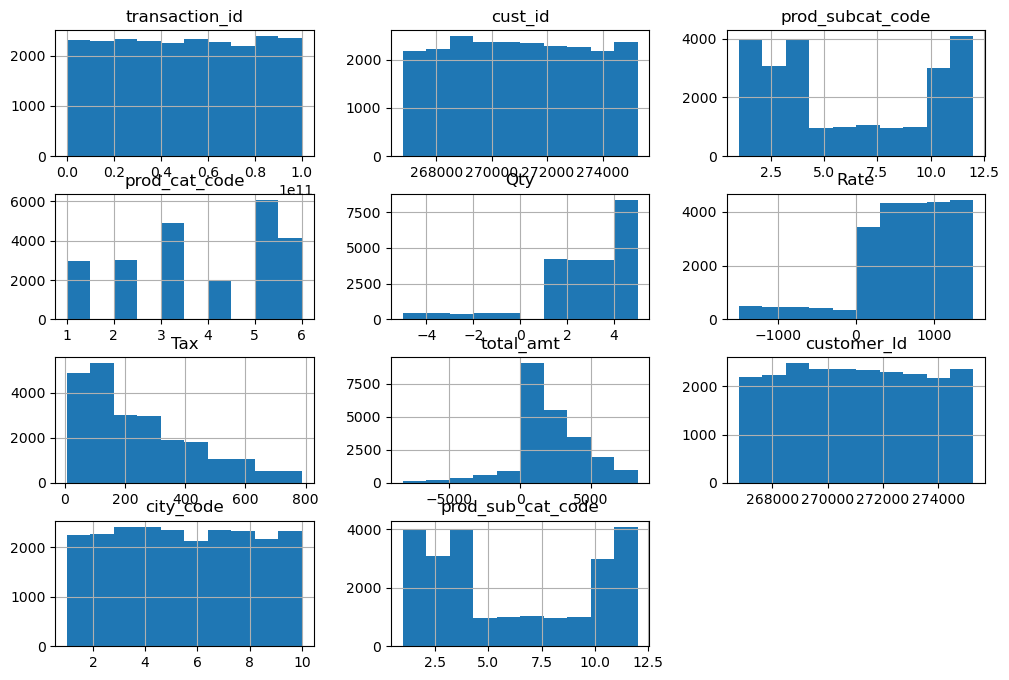

In [24]:
num_df.hist(figsize = (12,8))
plt.show()

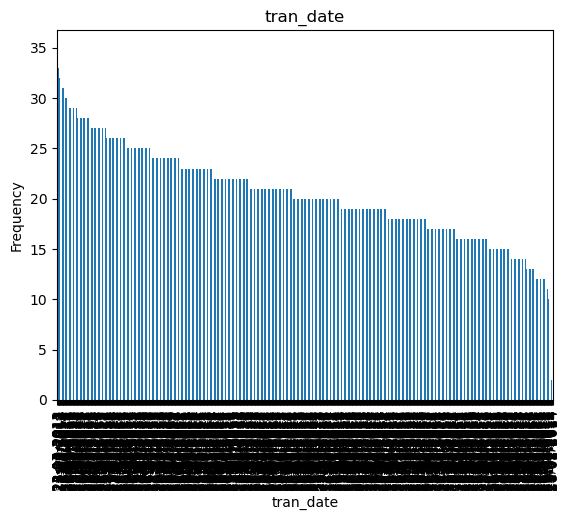

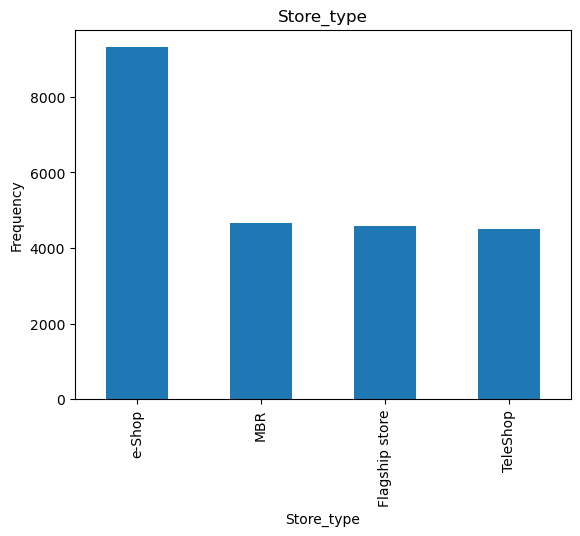

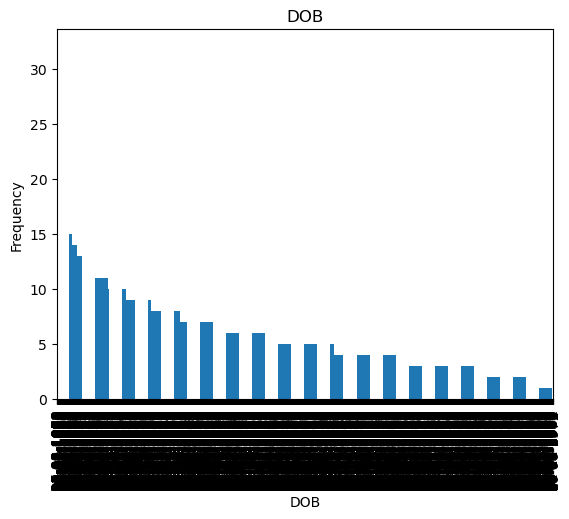

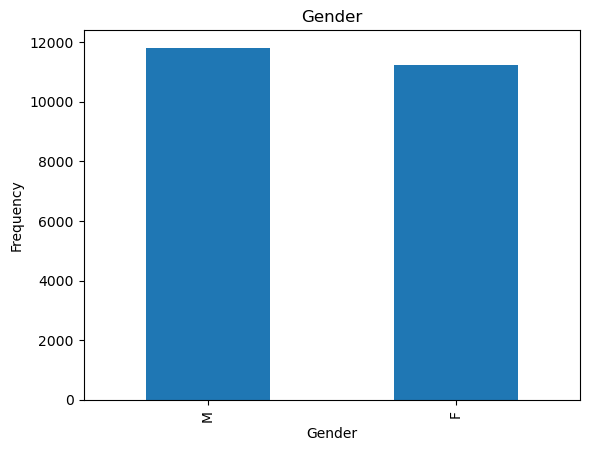

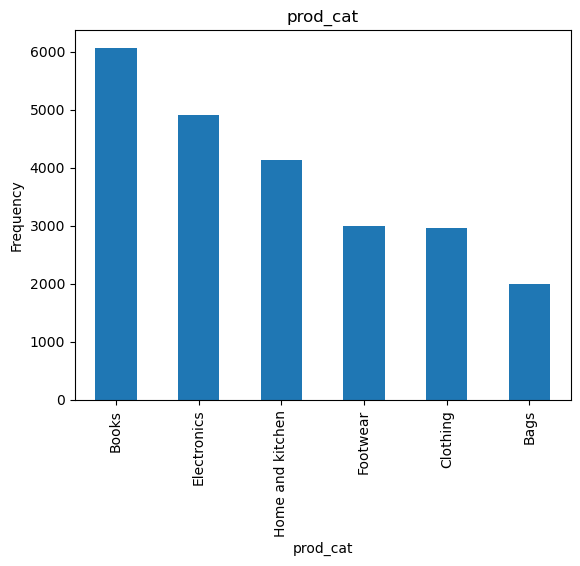

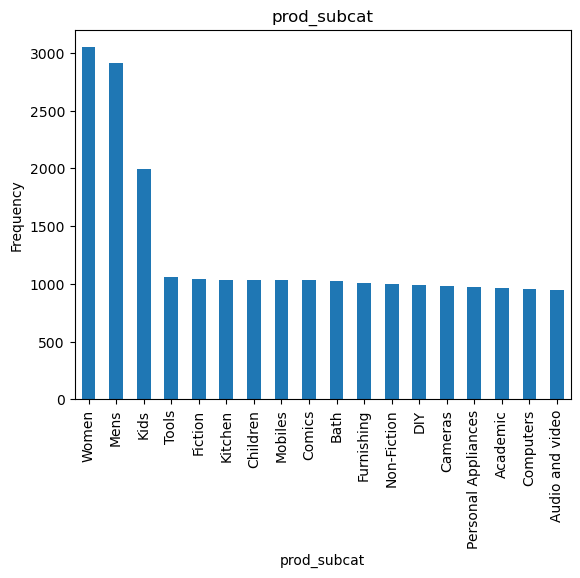

In [26]:
for col in cat_df.columns:
    cat_df[col].value_counts().plot(kind = 'bar')
    plt.title(col)
    plt.ylabel('Frequency')
    plt.show()

In [30]:
#4. Calculate the following information using the merged dataset :

In [31]:
Customer_final.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop,270351,26-09-1981,M,5.0,Clothing,1,Women
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop,270384,11-05-1973,F,8.0,Electronics,5,Computers
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop,271509,08-06-1981,M,3.0,Home and kitchen,11,Bath
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY


In [32]:
#a. Time period of the available transaction data
min_date = Customer_final['tran_date'].min()
max_date = Customer_final['tran_date'].max()
print(f"The timeline is from {min_date} to {max_date}")

The timeline is from 1/1/2012 to 9/9/2013


In [35]:
#b. Count of transactions where the total amount of transaction was negative
negative_trans = Customer_final.loc[Customer_final['total_amt'] < 0, :]
negative_trans.shape[0]

2177

In [36]:
#5. Analyze which product categories are more popular among females vs male customers.

Text(0, 0.5, 'Sales')

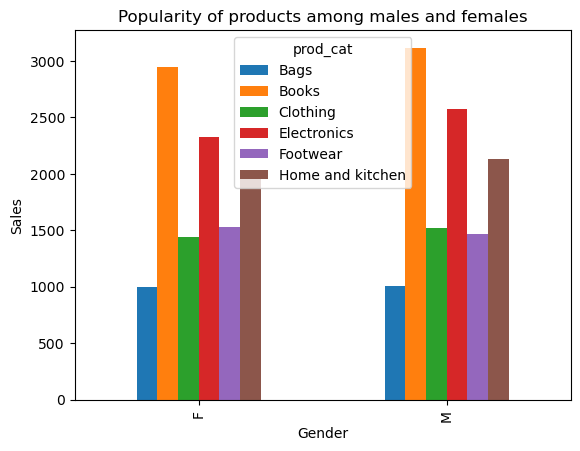

In [40]:
pd.crosstab(Customer_final['Gender'], Customer_final['prod_cat']).plot(kind = 'bar')
plt.title("Popularity of products among males and females")
plt.xlabel("Gender")
plt.ylabel("Sales")

In [41]:
#6. Which City code has the maximum customers and what was the percentage of customers from
#that city?

In [51]:
max_city = Customer_final['city_code'].value_counts().idxmax()
max_val = Customer_final['city_code'].value_counts().max()
tot_num = Customer_final['city_code'].count()
percentage = round((max_val/tot_num) * 100,2)
print(f"City with the highest code {max_city}\nHighest value {max_val}\nPercentage {percentage}")

City with the highest code 4.0
Highest value 2422
Percentage 10.51


In [52]:
#7. Which store type sells the maximum products by value and by quantity?
Customer_final.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop,270351,26-09-1981,M,5.0,Clothing,1,Women
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop,270384,11-05-1973,F,8.0,Electronics,5,Computers
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop,271509,08-06-1981,M,3.0,Home and kitchen,11,Bath
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop,273420,27-07-1992,M,8.0,Books,6,DIY


In [56]:
g1 = Customer_final.groupby(by = ['Store_type']).agg(Total_Qty = ('Qty', 'sum'),
                                                Total_Amt = ('total_amt', 'sum'))
g1

,Total_Qty,Total_Amt
Store_type,,
Flagship store,11133,9.715688e+06
MBR,11194,9.674486e+06
TeleShop,10984,9.364781e+06
e-Shop,22763,1.982482e+07


In [58]:
max_val = g1['Total_Qty'].idxmax()
max_val

'e-Shop'

In [59]:
max_val = g1['Total_Amt'].idxmax()
max_val

'e-Shop'

In [60]:
#8. What was the total amount earned from the "Electronics" and "Clothing" categories from
#Flagship Stores?

In [66]:
f1 = Customer_final.loc[(Customer_final['Store_type'] == 'Flagship store') &
                   (Customer_final['prod_cat'].isin(['Electronics', 'Clothing']))]

In [70]:
f1.groupby(by = ['prod_cat']).agg(TotalAmount = ('total_amt', 'sum')).reset_index()

,prod_cat,TotalAmount
0,Clothing,1194423.23
1,Electronics,2215136.04


In [71]:
#9. What was the total amount earned from "Male" customers under the "Electronics" category?

In [73]:
f2 = Customer_final.loc[(Customer_final['Gender'] == 'M') &
                        (Customer_final['prod_cat'] == 'Electronics')]

In [77]:
f2.groupby(by = ['Gender']).agg(Total_amount = ('total_amt', 'sum')).reset_index()

,Gender,Total_amount
0,M,5703109.425


In [78]:
#10. How many customers have more than 10 unique transactions, after removing all transactions
#which have any negative amounts?

In [79]:
pos_trans = Customer_final.loc[Customer_final['total_amt'] > 0, :]
pos_trans

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
10,29258453508,270384,20-02-2014,5,3,5,1497,785.925,8270.925,e-Shop,270384,11-05-1973,F,8.0,Electronics,5,Computers
11,25455265351,267750,20-02-2014,12,6,3,1360,428.400,4508.400,e-Shop,267750,13-10-1986,M,1.0,Home and kitchen,12,Tools
12,1571002198,275023,20-02-2014,6,5,4,587,246.540,2594.540,e-Shop,275023,09-03-1971,M,6.0,Books,6,DIY
14,36554696014,269345,20-02-2014,3,5,3,1253,394.695,4153.695,e-Shop,269345,26-06-1970,F,10.0,Books,3,Comics
15,56814940239,268799,20-02-2014,7,5,5,368,193.200,2033.200,e-Shop,268799,27-06-1979,M,9.0,Books,7,Fiction
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23048,94340757522,274550,25-01-2011,12,5,1,1264,132.720,1396.720,e-Shop,274550,21-02-1972,M,7.0,Books,12,Academic
23049,89780862956,270022,25-01-2011,4,1,1,677,71.085,748.085,e-Shop,270022,27-04-1984,M,9.0,Clothing,4,Mens
23050,85115299378,271020,25-01-2011,2,6,4,1052,441.840,4649.840,MBR,271020,20-06-1976,M,8.0,Home and kitchen,2,Furnishing
23051,72870271171,270911,25-01-2011,11,5,3,1142,359.730,3785.730,TeleShop,270911,22-05-1970,M,2.0,Books,11,Children


In [93]:
trans_count = pos_trans.groupby(by = ['cust_id']).agg(Count = ('transaction_id', 'count')).reset_index()

In [94]:
trans_count[trans_count > 10]

,cust_id,Count
0,266783,NaN
1,266784,NaN
2,266785,NaN
3,266788,NaN
4,266794,11.0
...,...,...
5501,275257,NaN
5502,275261,NaN
5503,275262,NaN
5504,275264,NaN


In [99]:
trans_count.loc[trans_count['Count']>10].count()

cust_id    6
Count      6
dtype: int64

In [100]:
#11. For all customers aged between 25 - 35, find out:
#a. What was the total amount spent for “Electronics” and “Books” product categories?
#b. What was the total amount spent by these customers between 1st Jan, 2014 to 1st Mar, 2014?

In [119]:
curr_date = datetime.datetime.now().strftime('%d-%m-%Y')
curr_date = datetime.datetime.strptime(curr_date, '%d-%m-%Y')

In [122]:
Customer_final['DOB'] = pd.to_datetime(Customer_final['DOB'], dayfirst = True)
Customer_final['DOB'] = Customer_final['DOB'].dt.strftime('%d-%m-%Y')
Customer_final['DOB'] = pd.to_datetime(Customer_final['DOB'])
pos = Customer_final.columns.get_loc('DOB')
Customer_final.insert(pos+1,
                      'Age',
                      (curr_date - Customer_final['DOB']).dt.days//365)

C:\Users\dayee\AppData\Local\Temp\ipykernel_21484\2614521012.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  Customer_final['DOB'] = pd.to_datetime(Customer_final['DOB'])


In [129]:
f3 = Customer_final.loc[(Customer_final['Age'].between(25,35)) &
                        (Customer_final['prod_cat'].isin(['Electronics', 'Books']))].reset_index()
f3.groupby(by = ['prod_cat']).agg(Total_amount = ('total_amt', 'sum')).reset_index()

,prod_cat,Total_amount
0,Books,1462226.610
1,Electronics,1158222.325


In [149]:
f3['tran_date'] = pd.to_datetime(Customer_final['tran_date'], format = 'mixed', dayfirst = True)
f4 = f3.loc[(f3['tran_date']>= '2014-01-01') & (f3['tran_date'] <= '2014-03-01')]
f4.groupby(by = ['prod_cat']).agg(Total_amount = ('total_amt', 'sum')).reset_index()

,prod_cat,Total_amount
0,Books,1211371.720
1,Electronics,955717.815
